# Лабораторная работа №9. Optical Flow и least squares

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №9».

**Данные.** `data/vtest_0.png`, `data/vtest_1.png` — два соседних кадра (768×576, 10 кадров/с) из ролика `vtest.avi` в примерах OpenCV: пешеходы на площади, камера неподвижна. Для контролируемого опыта с известным ответом — `data/building.jpg`, сдвинутый на заданную долю пикселя.

## 1. О чём эта работа

### Знакомый пример

Оптическая мышь. В её дне — крошечная камера, которая тысячи раз в секунду снимает поверхность стола. Сравнивая соседние кадры, мышь определяет, на сколько и куда сдвинулась картинка, и двигает курсор. Стабилизация видео в телефоне и «трекинг» объекта в видеоредакторе работают на том же принципе.

### Основная идея

Есть два кадра, снятые один за другим. Для выбранной точки хотим узнать, куда она сместилась: вектор $(u,v)$ в пикселях. Предположим, что **точка не меняет яркость**, а только переезжает. Тогда изменение яркости в данном пикселе между кадрами целиком объясняется тем, что «на это место приехал сосед». Насколько сосед отличается, говорит градиент (лабораторная 4). Получается уравнение, связывающее сдвиг, градиент и изменение яркости во времени.

Беда в том, что уравнение одно, а неизвестных два. Выход (Лукас и Канаде): считать, что все пиксели маленького окна вокруг точки движутся одинаково. Тогда уравнений столько, сколько пикселей в окне, — больше, чем неизвестных, — и систему решают методом наименьших квадратов.

### Понятия

- **Optical flow** — поле векторов $(u,v)$: смещение каждой точки изображения между кадрами.
- **Brightness constancy** — предположение о постоянстве яркости движущейся точки.
- **Ряд Тейлора первого порядка** — приближение функции вблизи точки касательной: $f(x+h)\approx f(x)+f'(x)h$. Чем меньше $h$, тем точнее. Для функции нескольких переменных добавляются слагаемые с частными производными по каждой.
- **$I_t$** — производная яркости по времени: разность второго и первого кадров в одном и том же пикселе.
- **Переопределённая система** — уравнений больше, чем неизвестных; точного решения обычно нет.
- **Least squares** (наименьшие квадраты) — выбрать решение, при котором сумма квадратов невязок минимальна. Этот приём уже встречался в лабораторной 7 (оценка $f_x$).
- **Normal equations** — уравнения, которым удовлетворяет решение наименьших квадратов: $A^TA\,x=A^Tb$.
- **Число обусловленности** (condition number) — во сколько раз относительная ошибка в данных может усилиться в ответе. Для матрицы $A$ это отношение наибольшего сингулярного числа к наименьшему: $\kappa=\sigma_{max}/\sigma_{min}$. Около 1 — задача устойчива; тысячи — ответ ненадёжен.
- **Aperture problem** (проблема апертуры). Посмотрите на движущуюся длинную прямую линию через маленькое отверстие: видно только движение поперёк линии, а скользит ли она ещё и вдоль себя — узнать нельзя.

### Формулы

$$I(x+u,\,y+v,\,t+1)\approx I+I_xu+I_yv+I_t\qquad\Rightarrow\qquad I_xu+I_yv+I_t=0$$

Для окна из $n$ пикселей: $A\,[u,v]^T=b$, где в строке $i$ матрицы $A$ стоят $(I_x,I_y)$ пикселя $i$, а $b_i=-I_t$.

$$\hat v=(A^TA)^{-1}A^Tb$$

Обратите внимание: $A^TA=\begin{bmatrix}\sum I_x^2&\sum I_xI_y\\\sum I_xI_y&\sum I_y^2\end{bmatrix}$ — это structure tensor $M$ из лабораторной 5. Там его собственные значения отличали угол от границы; здесь они же определяют, можно ли найти движение.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

FRAME_1, FRAME_2 = "data/vtest_0.png", "data/vtest_1.png"
HALF = 7                  # окно (2·HALF+1)² = 15×15
BLUR_SIGMA = 1.0          # сглаживание перед дифференцированием
rng = np.random.default_rng(0)

## 2. Вопрос 1 — вывод уравнения optical flow

> Выведите $I_xu+I_yv+I_t=0$ из brightness constancy с помощью Taylor expansion первого порядка.

**Шаг 1. Предположение.** Точка, находившаяся в момент $t$ в $(x,y)$, в момент $t+1$ оказалась в $(x+u,y+v)$ и сохранила яркость:

$$I(x+u,\,y+v,\,t+1)=I(x,y,t)$$

**Шаг 2. Разложение.** $I$ — функция трёх переменных $(x,y,t)$. Все три изменились: на $u$, $v$ и 1. Тейлор первого порядка — старое значение плюс «производная × приращение» по каждой переменной:

$$I(x+u,\,y+v,\,t+1)\approx I(x,y,t)+I_x\cdot u+I_y\cdot v+I_t\cdot1$$

**Шаг 3. Подстановка.** Левая часть по шагу 1 равна $I(x,y,t)$:

$$I(x,y,t)\approx I(x,y,t)+I_xu+I_yv+I_t$$

**Шаг 4.** $I(x,y,t)$ сокращается:

$$I_xu+I_yv+I_t=0$$

**Смысл.** Перепишем как $I_t=-(I_xu+I_yv)$: яркость в пикселе изменилась потому, что картинка «проехала» по нему на $(u,v)$, а яркость вдоль направления движения менялась со скоростью, заданной градиентом.

**Два предположения, которые были сделаны:** яркость точки постоянна (шаг 1) и смещение мало (шаг 2 — иначе касательная плохо приближает функцию). Нарушение любого из них — источник ошибок; см. раздел 5.

**Почему одного уравнения мало.** Это уравнение прямой на плоскости $(u,v)$. Ему удовлетворяет бесконечно много сдвигов. Однозначно находится только составляющая вдоль градиента: $-I_t/|\nabla I|$. Это и есть проблема апертуры.

In [2]:
# численная проверка на гладкой функции: сдвигаем «изображение» на (u, v) и сравниваем обе части уравнения
def scene(x, y):
    return 100 + 40 * np.sin(0.05 * x) * np.cos(0.04 * y) + 0.3 * x

xs, ys = np.meshgrid(np.arange(100.0), np.arange(100.0))
u_true, v_true = 0.3, -0.2
I1 = scene(xs, ys)
I2 = scene(xs - u_true, ys - v_true)             # картинка сдвинулась на (u, v)
Ix = (I1[:, 2:] - I1[:, :-2])[1:-1] / 2
Iy = (I1[2:, :] - I1[:-2, :])[:, 1:-1] / 2
It = (I2 - I1)[1:-1, 1:-1]
resid = Ix * u_true + Iy * v_true + It
print(f"типичная величина |I_t|: {np.abs(It).mean():.4f}")
print(f"остаток |I_x u + I_y v + I_t| : {np.abs(resid).mean():.5f} — на порядки меньше")
for scale in (1, 5, 20):
    I2s = scene(xs - scale * u_true, ys - scale * v_true)
    r = Ix * scale * u_true + Iy * scale * v_true + (I2s - I1)[1:-1, 1:-1]
    print(f"  сдвиг ×{scale:2d} ({scale * u_true:.1f}, {scale * v_true:.1f}) px: относительный остаток = {np.abs(r).mean() / np.abs((I2s - I1)[1:-1, 1:-1]).mean():.3f}")

типичная величина |I_t|: 0.3252
остаток |I_x u + I_y v + I_t| : 0.00339 — на порядки меньше
  сдвиг × 1 (0.3, -0.2) px: относительный остаток = 0.010
  сдвиг × 5 (1.5, -1.0) px: относительный остаток = 0.052
  сдвиг ×20 (6.0, -4.0) px: относительный остаток = 0.202


**Итог вопроса 1:** $I_xu+I_yv+I_t=0$. Проверка показывает и границу применимости: при сдвиге в доли пикселя уравнение выполняется почти точно, при сдвиге в несколько пикселей линейное приближение разваливается.

## 3. Вопрос 2 — least squares и обусловленность

> Для `A=[[1,0],[0,1],[1,1]]`, `b=[1,2,2]^T` решите least squares. Объясните связь большого condition number $A^TA$ с aperture problem.

Система из трёх уравнений с двумя неизвестными:

$$u=1,\qquad v=2,\qquad u+v=2$$

Первые два дают $u+v=3$, третье требует 2 — противоречие. Ищем компромисс.

**Шаг 1.** $A^TA$: столбцы $A$ — $a_1=(1,0,1)$, $a_2=(0,1,1)$. Скалярные произведения: $a_1\cdot a_1=2$, $a_1\cdot a_2=1$, $a_2\cdot a_2=2$.

$$A^TA=\begin{bmatrix}2&1\\1&2\end{bmatrix}$$

**Шаг 2.** $A^Tb=(a_1\cdot b,\ a_2\cdot b)=(1+0+2,\ 0+2+2)=(3,4)$.

**Шаг 3.** Обратная матрица 2×2: $\begin{bmatrix}a&b\\c&d\end{bmatrix}^{-1}=\frac{1}{ad-bc}\begin{bmatrix}d&-b\\-c&a\end{bmatrix}$. Определитель $=4-1=3$:

$$(A^TA)^{-1}=\frac13\begin{bmatrix}2&-1\\-1&2\end{bmatrix}$$

**Шаг 4.**

$$\begin{bmatrix}u\\v\end{bmatrix}=\frac13\begin{bmatrix}2\cdot3-1\cdot4\\-1\cdot3+2\cdot4\end{bmatrix}=\frac13\begin{bmatrix}2\\5\end{bmatrix}=\begin{bmatrix}0.667\\1.667\end{bmatrix}$$

**Проверка.** Невязки $Ax-b$: $(0.667-1,\ 1.667-2,\ 2.333-2)=(-\tfrac13,-\tfrac13,+\tfrac13)$. Противоречие в единицу распределилось поровну между тремя уравнениями.

### Condition number и aperture problem

Собственные значения $A^TA$: $\lambda^2-4\lambda+3=0\Rightarrow\lambda=3$ и $\lambda=1$. Число обусловленности $A^TA$ равно $3/1=3$ — задача хорошо обусловлена.

Для optical flow $A^TA$ — structure tensor окна, а его собственные значения — «сколько градиента» в окне вдоль двух главных направлений.

- **Угол:** оба $\lambda$ большие, $\kappa$ мало. Градиенты в окне смотрят в разные стороны, уравнения ограничивают $(u,v)$ с двух сторон — решение устойчиво.
- **Прямая граница:** все градиенты параллельны, $\lambda_2\approx0$, $\kappa$ огромно. Все уравнения говорят одно и то же — «составляющая сдвига поперёк границы равна такой-то». О сдвиге вдоль границы уравнения молчат. $(A^TA)^{-1}$ содержит множитель $1/\lambda_2$, поэтому шум в данных усиливается в $1/\lambda_2$ раз именно в этом направлении.
- **Ровная область:** оба $\lambda\approx0$, градиентов нет, движение не определяется вовсе.

Большое число обусловленности — математическая запись проблемы апертуры: одна составляющая движения наблюдается плохо, и её оценка определяется шумом.

In [3]:
A = np.array([[1.0, 0], [0, 1], [1, 1]]); b = np.array([1.0, 2, 2])
AtA, Atb = A.T @ A, A.T @ b
x_ne = np.linalg.inv(AtA) @ Atb
x_ls, res, rank, sv = np.linalg.lstsq(A, b, rcond=None)
print("AᵀA =\n", AtA, "\nAᵀb =", Atb)
print("через нормальные уравнения:", x_ne, " через lstsq:", x_ls)
print("невязки Ax − b:", A @ x_ls - b)
print("собственные значения AᵀA:", np.linalg.eigvalsh(AtA), " сингулярные числа A:", sv)
print(f"cond(A) = {sv[0] / sv[-1]:.4f}, cond(AᵀA) = {np.linalg.cond(AtA):.4f} = cond(A)²")

print("\nвсе градиенты почти параллельны (прямая граница):")
A_edge = np.array([[1.0, 1.0], [2.0, 2.001], [3.0, 3.0]])
b_edge = A_edge @ np.array([0.5, 0.5])                         # истинный сдвиг (0.5, 0.5)
print("  cond(A) =", round(np.linalg.cond(A_edge), 1))
print("  без шума:", np.linalg.lstsq(A_edge, b_edge, rcond=None)[0])
print("  шум 0.001 в b:", np.linalg.lstsq(A_edge, b_edge + np.array([0.001, -0.001, 0.001]), rcond=None)[0])

AᵀA =
 [[2. 1.]
 [1. 2.]] 
Aᵀb = [3. 4.]
через нормальные уравнения: [0.6667 1.6667]  через lstsq: [0.6667 1.6667]
невязки Ax − b: [-0.3333 -0.3333  0.3333]
собственные значения AᵀA: [1. 3.]  сингулярные числа A: [1.7321 1.    ]
cond(A) = 1.7321, cond(AᵀA) = 3.0000 = cond(A)²

все градиенты почти параллельны (прямая граница):
  cond(A) = 8855.6
  без шума: [0.5 0.5]
  шум 0.001 в b: [ 2.3004 -1.3   ]


**Итог вопроса 2:** $(u,v)=(2/3,\ 5/3)\approx(0.667,\ 1.667)$.

Последний пример: при почти параллельных градиентах шум в третьем знаке правой части меняет ответ на единицы. При этом сумма $u+v$ (составляющая вдоль градиента) остаётся близкой к 1 — наблюдаемая часть движения устойчива, ненаблюдаемая — нет.

## 4. Задание 3 — код и эксперимент

### Шаги 1–3. Кадры, точки Shi–Tomasi, Lucas–Kanade из OpenCV

`calcOpticalFlowPyrLK` — пирамидальный LK: сначала оценивает движение на уменьшенных копиях кадра (там большие сдвиги становятся малыми), потом уточняет на исходном. Чтобы отобрать надёжно отслеженные точки, делаем проверку «туда-обратно»: трекаем точку с кадра 1 на кадр 2, потом обратно; у хорошей точки возврат попадает в исходное место.

кадры: (576, 768)
точек: 300, прошли проверку туда-обратно: 286, из них движутся (>0.4 px): 50
смещение движущихся точек: медиана 2.28 px, максимум 6.22 px


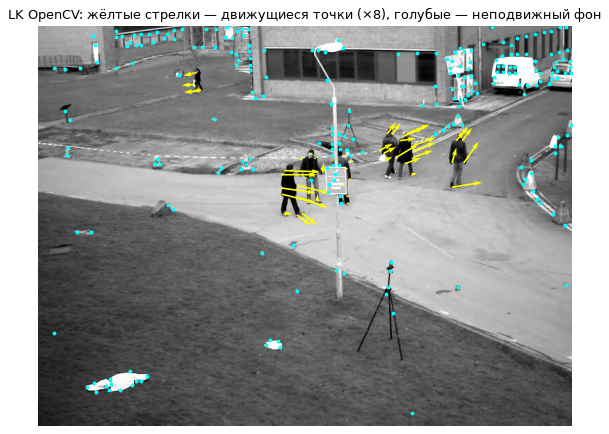

In [4]:
f1 = cv2.imread(FRAME_1, cv2.IMREAD_GRAYSCALE)
f2 = cv2.imread(FRAME_2, cv2.IMREAD_GRAYSCALE)
assert f1 is not None and f2 is not None
print("кадры:", f1.shape)

p0 = cv2.goodFeaturesToTrack(f1, maxCorners=300, qualityLevel=0.01, minDistance=7, blockSize=7)
lk_params = dict(winSize=(2 * HALF + 1, 2 * HALF + 1), maxLevel=2, criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
p1, st, _ = cv2.calcOpticalFlowPyrLK(f1, f2, p0, None, **lk_params)
p0b, stb, _ = cv2.calcOpticalFlowPyrLK(f2, f1, p1, None, **lk_params)

pts = p0.reshape(-1, 2); flow_cv = (p1 - p0).reshape(-1, 2)
fb_err = np.linalg.norm(p0b.reshape(-1, 2) - pts, axis=1)
ok = (st.ravel() == 1) & (stb.ravel() == 1) & (fb_err < 0.3)
speed = np.linalg.norm(flow_cv, axis=1)
moving = ok & (speed > 0.4)
print(f"точек: {len(pts)}, прошли проверку туда-обратно: {ok.sum()}, из них движутся (>0.4 px): {moving.sum()}")
print(f"смещение движущихся точек: медиана {np.median(speed[moving]):.2f} px, максимум {speed[moving].max():.2f} px")

plt.figure(figsize=(9, 6.5))
plt.imshow(f1)
plt.quiver(pts[moving, 0], pts[moving, 1], flow_cv[moving, 0], flow_cv[moving, 1], color="yellow", angles="xy", scale_units="xy", scale=0.12, width=0.003)
plt.scatter(pts[ok & ~moving, 0], pts[ok & ~moving, 1], s=6, c="cyan")
plt.title("LK OpenCV: жёлтые стрелки — движущиеся точки (×8), голубые — неподвижный фон"); plt.axis("off"); plt.show()

### Шаги 4–8. Одна точка: собираем A и b, решаем lstsq, сравниваем с OpenCV

Для окна 15×15 вокруг точки:

- $I_x,I_y$ — производные первого кадра (Собель, делённый на 8, — та же центральная разность со сглаживанием, см. лабораторную 4);
- $I_t=I_2-I_1$;
- каждая из 225 строк матрицы $A$ — $(I_x,I_y)$ одного пикселя, $b=-I_t$.

Перед дифференцированием кадры слегка сглаживаются (σ=1): производная усиливает шум.

Решаем `np.linalg.lstsq` — он использует SVD и не вычисляет $(A^TA)^{-1}$ (почему это важно — вопрос 3 на защите).

**Итерации.** Уравнение выведено для малого сдвига. Если точка сдвинулась на пиксель и больше, один шаг даёт заниженную оценку. Стандартное лечение (его делает и OpenCV): найти сдвиг, взять окно второго кадра со смещением на найденную величину, снова посчитать $I_t$ и найти поправку; повторять, пока поправка не станет малой.

точка (394, 185); A: (225, 2), b: (225,)
сингулярные числа A: [344.6263 268.8691]  condition number: 1.28
u,v собственные, один шаг : [-0.6019 -0.2923]
u,v собственные, итерации : [-0.5368 -0.2732] (итераций: 4)
u,v OpenCV                : [-0.5168 -0.2994]
расхождение с OpenCV: один шаг 0.085 px, итерации 0.033 px


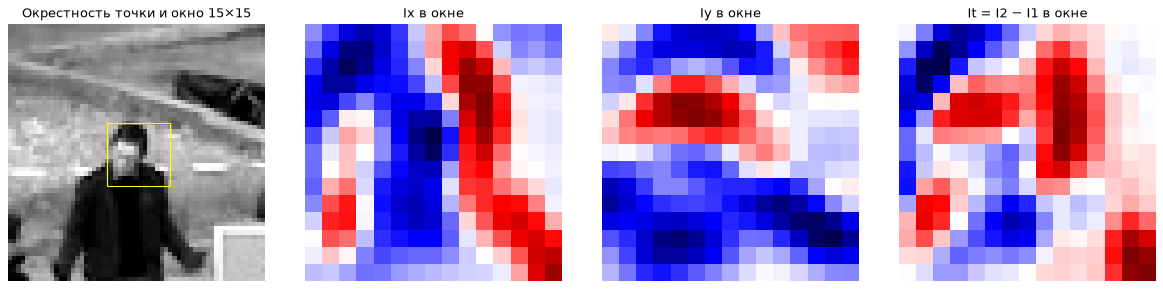

In [5]:
def prep(img):
    return cv2.GaussianBlur(img.astype(np.float32), (0, 0), BLUR_SIGMA)

def build_system(I1, I2, x, y, half=HALF, shift=(0.0, 0.0)):
    """A = [Ix, Iy], b = −It для окна вокруг (x, y); окно второго кадра смещено на shift."""
    size = (2 * half + 1, 2 * half + 1)
    Ix = cv2.Sobel(I1, cv2.CV_32F, 1, 0, ksize=3) / 8.0
    Iy = cv2.Sobel(I1, cv2.CV_32F, 0, 1, ksize=3) / 8.0
    w1 = cv2.getRectSubPix(I1, size, (float(x), float(y)))
    w2 = cv2.getRectSubPix(I2, size, (float(x + shift[0]), float(y + shift[1])))
    Ix_window = cv2.getRectSubPix(Ix, size, (float(x), float(y)))
    Iy_window = cv2.getRectSubPix(Iy, size, (float(x), float(y)))
    It_window = w2 - w1
    A = np.column_stack([Ix_window.ravel(), Iy_window.ravel()]).astype(np.float64)
    b = -It_window.ravel().astype(np.float64)
    return A, b

def lk_one_step(I1, I2, x, y):
    A, b = build_system(I1, I2, x, y)
    flow, residuals, rank, s = np.linalg.lstsq(A, b, rcond=None)
    cond = s[0] / s[-1] if s[-1] > 1e-12 else np.inf
    return flow, cond, s

def lk_iterative(I1, I2, x, y, iters=20, tol=1e-3):
    flow = np.zeros(2)
    for k in range(iters):
        A, b = build_system(I1, I2, x, y, shift=flow)
        delta = np.linalg.lstsq(A, b, rcond=None)[0]
        flow = flow + delta
        if np.linalg.norm(delta) < tol:
            break
    return flow, k + 1

g1, g2 = prep(f1), prep(f2)

# устойчиво отслеживаемая движущаяся точка: лучший «угол» среди движущихся
quality = cv2.cornerMinEigenVal(f1, blockSize=2 * HALF + 1)
cand = np.nonzero(moving)[0]
best = cand[np.argmax([quality[int(pts[i, 1]), int(pts[i, 0])] for i in cand])]
x0, y0 = pts[best]

A, b = build_system(g1, g2, x0, y0)
flow1, cond1, s1 = lk_one_step(g1, g2, x0, y0)
flow_it, n_it = lk_iterative(g1, g2, x0, y0)
print(f"точка ({x0:.0f}, {y0:.0f}); A: {A.shape}, b: {b.shape}")
print("сингулярные числа A:", s1, " condition number:", round(cond1, 2))
print("u,v собственные, один шаг :", flow1)
print(f"u,v собственные, итерации : {flow_it} (итераций: {n_it})")
print("u,v OpenCV                :", flow_cv[best])
print(f"расхождение с OpenCV: один шаг {np.linalg.norm(flow1 - flow_cv[best]):.3f} px, итерации {np.linalg.norm(flow_it - flow_cv[best]):.3f} px")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
size = (2 * HALF + 1,) * 2
ax[0].imshow(cv2.getRectSubPix(f1, (61, 61), (float(x0), float(y0)))); ax[0].add_patch(plt.Rectangle((30 - HALF, 30 - HALF), 2 * HALF + 1, 2 * HALF + 1, fill=False, ec="yellow")); ax[0].set_title("Окрестность точки и окно 15×15")
ax[1].imshow(A[:, 0].reshape(size), cmap="seismic"); ax[1].set_title("Ix в окне")
ax[2].imshow(A[:, 1].reshape(size), cmap="seismic"); ax[2].set_title("Iy в окне")
ax[3].imshow(-b.reshape(size), cmap="seismic"); ax[3].set_title("It = I2 − I1 в окне")
for a_ in ax: a_.axis("off")
plt.tight_layout(); plt.show()

### Шаги 9–10. Точки с разной обусловленностью

Для каждой движущейся точки считаем число обусловленности $\kappa$ и берём три точки с наименьшим и три с наибольшим $\kappa$.

In [6]:
rows = []
for i in np.nonzero(moving)[0]:
    x, y = pts[i]
    fl1, c, _ = lk_one_step(g1, g2, x, y)
    fli, _ = lk_iterative(g1, g2, x, y)
    rows.append((i, c, fl1, fli))
rows.sort(key=lambda r: r[1])
chosen = rows[:3] + rows[-3:]

print(f"{'Точка':>12}{'Тип области':>14}{'u,v свои (1 шаг)':>22}{'u,v свои (итерации)':>24}{'u,v OpenCV':>20}{'Condition':>11}{'|Δ| с OpenCV':>14}")
for n, (i, c, fl1, fli) in enumerate(chosen):
    kind = "мин. κ" if n < 3 else "макс. κ"
    x, y = pts[i]
    print(f"{f'({x:.0f},{y:.0f})':>12}{kind:>14}{f'({fl1[0]:+.2f}, {fl1[1]:+.2f})':>22}{f'({fli[0]:+.2f}, {fli[1]:+.2f})':>24}{f'({flow_cv[i,0]:+.2f}, {flow_cv[i,1]:+.2f})':>20}{c:11.1f}{np.linalg.norm(fli - flow_cv[i]):14.3f}")

conds = np.array([r[1] for r in rows]); diffs = np.array([np.linalg.norm(r[3] - flow_cv[r[0]]) for r in rows])
half_n = len(rows) // 2
print(f"\nвсе {len(rows)} движущихся точек: медианное расхождение с OpenCV — {np.median(diffs[:half_n]):.3f} px у половины с меньшим κ, {np.median(diffs[half_n:]):.3f} px у половины с большим κ")

       Точка   Тип области      u,v свои (1 шаг)     u,v свои (итерации)          u,v OpenCV  Condition  |Δ| с OpenCV
   (401,252)        мин. κ        (+0.10, -1.07)          (+0.11, -1.11)      (+0.13, -1.19)        1.1         0.086
   (491,179)        мин. κ        (+1.77, -0.79)          (+2.23, -1.38)      (+2.24, -1.17)        1.2         0.203
   (595,232)        мин. κ        (+0.60, -0.79)          (+5.57, -1.23)      (+5.17, -0.84)        1.3         0.557
   (349,233)       макс. κ        (+2.23, -0.18)          (+5.92, +0.85)      (+5.91, +0.87)        3.8         0.025
   (372,229)       макс. κ        (+2.37, +0.55)          (+5.68, +1.31)      (+5.69, +1.41)        4.1         0.093
   (372,246)       макс. κ        (+2.30, -1.41)          (+5.23, +2.26)      (+5.27, +1.82)        4.2         0.448

все 50 движущихся точек: медианное расхождение с OpenCV — 0.109 px у половины с меньшим κ, 0.087 px у половины с большим κ


Три наблюдения.

- **Точек на прямых границах среди отслеживаемых нет.** Наибольшее $\kappa$ — всего 4.2. Это не случайность: точки выбирал детектор Shi–Tomasi, который оставляет только места с большим $\lambda_{min}$, то есть именно те, где задача хорошо обусловлена. Поэтому на этих точках связи между $\kappa$ и расхождением с OpenCV не видно (медианы 0.11 и 0.09 px). Случай границы придётся создать специально — см. ниже.
- **Один шаг занижает большие смещения.** Там, где OpenCV показывает сдвиг 5–6 px, одношаговая оценка даёт 0.6–2.4 px. Итерации исправляют это и сходятся к значениям OpenCV с точностью 0.03–0.6 px.
- **На реальном видео истинное движение неизвестно:** мы сравниваем две оценки между собой. Чтобы увидеть ошибку относительно истины, нужен опыт с известным ответом.

### Контролируемый опыт: сдвиг известен

Берём `building.jpg` и сдвигаем его на $(0.6,\ -0.4)$ пикселя (субпиксельный сдвиг с интерполяцией). Истинный flow одинаков во всех точках. По карте structure tensor выбираем три точки: угол (оба собственных значения большие), прямую границу (одно большое, другое почти ноль) и ровную область (оба около нуля).

Затем добавляем к кадрам шум и повторяем оценку 200 раз — так видно, насколько оценка в каждой точке чувствительна к шуму.

истинный сдвиг: [ 0.6 -0.4]
Тип области            (x,y)       u,v собственные  ошибка, px   Condition     вдоль ∇I: оценка / истина     std оценки при шуме σ=3


угол               (812,524)      (+0.622, -0.430)       0.038         1.1               +0.713 / +0.675              (0.010, 0.011)


прямая граница     (801,506)      (+0.592, -0.815)       0.415        23.1               -0.649 / -0.627              (0.010, 0.127)


ровная область     (108,228)      (+0.000, +0.000)       0.721         inf               +0.000 / +0.600              (0.289, 0.317)


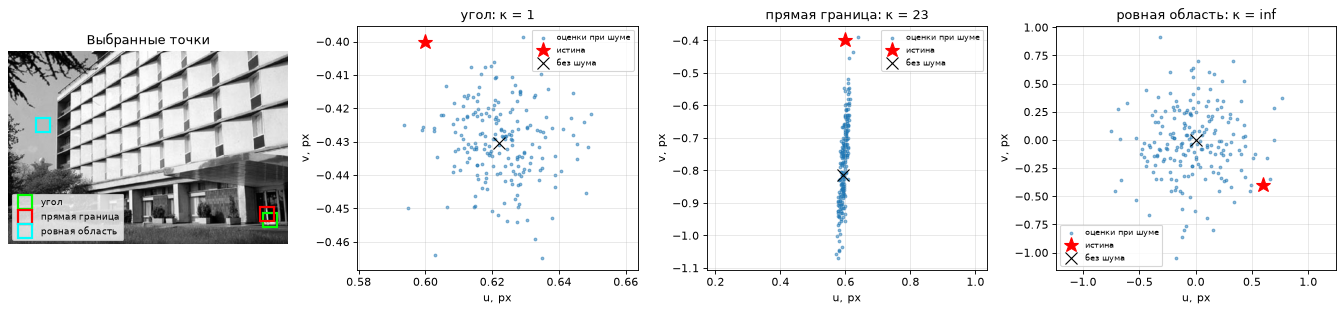

In [7]:
TRUE = np.array([0.6, -0.4])
base = cv2.imread("data/building.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float32)
Mshift = np.float32([[1, 0, TRUE[0]], [0, 1, TRUE[1]]])
moved = cv2.warpAffine(base, Mshift, base.shape[::-1], flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)

b1 = prep(base)
gx, gy = cv2.Sobel(b1, cv2.CV_32F, 1, 0, ksize=3) / 8, cv2.Sobel(b1, cv2.CV_32F, 0, 1, ksize=3) / 8
k = 2 * HALF + 1
Sxx, Syy, Sxy = (cv2.boxFilter(m, -1, (k, k), normalize=False) for m in (gx * gx, gy * gy, gx * gy))
root = np.sqrt(((Sxx - Syy) / 2) ** 2 + Sxy ** 2)
lam1, lam2 = (Sxx + Syy) / 2 + root, (Sxx + Syy) / 2 - root
inner = np.zeros_like(lam1, bool); inner[40:-40, 40:-40] = True

def pick(score):
    y, x = np.unravel_index(np.argmax(np.where(inner, score, -np.inf)), score.shape)
    return x, y

points = {
    "угол": pick(lam2),
    "прямая граница": pick(np.where(lam2 < 0.002 * lam1, lam1, -np.inf)),
    "ровная область": pick(-lam1),
}

print(f"истинный сдвиг: {TRUE}")
print(f"{'Тип области':16}{'(x,y)':>12}{'u,v собственные':>22}{'ошибка, px':>12}{'Condition':>12}{'вдоль ∇I: оценка / истина':>30}{'std оценки при шуме σ=3':>28}")
stats = {}
for name, (x, y) in points.items():
    A, b = build_system(b1, prep(moved), x, y)
    fl, _, _, s = np.linalg.lstsq(A, b, rcond=None)
    cond = s[0] / s[-1] if s[-1] > 1e-9 else np.inf
    n_dir = np.linalg.svd(A, full_matrices=False)[2][0]            # главное направление градиентов в окне
    trials = []
    for _ in range(200):
        n1 = prep(base + rng.normal(0, 3, base.shape).astype(np.float32)); n2 = prep(moved + rng.normal(0, 3, base.shape).astype(np.float32))
        An, bn = build_system(n1, n2, x, y)
        trials.append(np.linalg.lstsq(An, bn, rcond=None)[0])
    trials = np.array(trials)
    stats[name] = (x, y, fl, cond, trials)
    print(f"{name:16}{f'({x},{y})':>12}{f'({fl[0]:+.3f}, {fl[1]:+.3f})':>22}{np.linalg.norm(fl - TRUE):12.3f}{cond:12.1f}{f'{fl @ n_dir:+.3f} / {TRUE @ n_dir:+.3f}':>30}{f'({trials[:,0].std():.3f}, {trials[:,1].std():.3f})':>28}")

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].imshow(base); ax[0].axis("off"); ax[0].set_title("Выбранные точки")
for (name, (x, y, fl, cond, trials)), col in zip(stats.items(), ["lime", "red", "cyan"]):
    ax[0].plot(x, y, "s", mfc="none", mec=col, ms=12, mew=2, label=name)
ax[0].legend(fontsize=8, loc="lower left")
for a_, (name, (x, y, fl, cond, trials)) in zip(ax[1:], stats.items()):
    a_.scatter(trials[:, 0], trials[:, 1], s=6, alpha=0.5, label="оценки при шуме")
    a_.plot(*TRUE, "r*", ms=14, label="истина"); a_.plot(*fl, "kx", ms=10, label="без шума")
    a_.set(title=f"{name}: κ = {cond:.0f}", xlabel="u, px", ylabel="v, px"); a_.axis("equal"); a_.grid(alpha=0.3); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()

Столбец «вдоль ∇I» сравнивает оценку и истину в проекции на главное направление градиентов окна — ту составляющую движения, которую данные позволяют наблюдать.

На диаграммах рассеяния каждая синяя точка — оценка $(u,v)$ при одной реализации шума. У угла облако компактное и лежит на истине. У границы облако вытянуто в линию — вдоль направления самой границы: поперечная составляющая определена, продольная «плавает». У ровной области облако расползается во все стороны и с истиной не связано.

Для «границы» взята точка с отношением собственных значений меньше 0.002, это даёт $\kappa\approx23$. На идеально прямой границе без шума $\kappa$ было бы бесконечным; в реальном изображении всегда есть немного текстуры и шума, которые дают ненулевое второе сингулярное число.

## 5. Неудачные случаи

**1. Прямая граница и ровная область** — контролируемый опыт выше. Метод возвращает число в любом случае; отличить надёжный ответ от случайного можно только по сингулярным числам $A$.

**2. Большое смещение.** Нарушается предположение о малости сдвига. Проверим на том же угле: увеличиваем сдвиг и сравниваем один шаг, итерации и пирамидальный LK из OpenCV.

In [8]:
xc, yc = points["угол"]
print(f"{'истинный сдвиг, px':>22}{'один шаг':>20}{'итерации':>20}{'OpenCV (пирамида)':>22}")
for scale in (0.5, 1, 2, 4, 8, 15):
    t = TRUE * scale / np.linalg.norm(TRUE)
    mv = cv2.warpAffine(base, np.float32([[1, 0, t[0]], [0, 1, t[1]]]), base.shape[::-1], flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)
    A, b = build_system(b1, prep(mv), xc, yc)
    one = np.linalg.lstsq(A, b, rcond=None)[0]
    it, _ = lk_iterative(b1, prep(mv), xc, yc, iters=50)
    pcv, s_, _ = cv2.calcOpticalFlowPyrLK(base.astype(np.uint8), np.clip(mv, 0, 255).astype(np.uint8), np.float32([[[xc, yc]]]), None, winSize=(k, k), maxLevel=3)
    cvf = pcv.ravel() - np.array([xc, yc])
    fmt = lambda v: f"{np.linalg.norm(v - t):6.2f} px ошибка"
    print(f"{f'{scale:4.1f}  ({t[0]:+.2f},{t[1]:+.2f})':>22}{fmt(one):>20}{fmt(it):>20}{fmt(cvf):>22}")

# 3. нарушение brightness constancy: второй кадр стал светлее на 10 %
A, b = build_system(b1, prep(moved * 1.10), xc, yc)
print(f"\nвторой кадр ярче на 10 %: оценка {np.linalg.lstsq(A, b, rcond=None)[0]}, истина {TRUE}")
A0, b0 = build_system(b1, prep(moved), xc, yc)
print(f"без изменения яркости   : оценка {np.linalg.lstsq(A0, b0, rcond=None)[0]}")

    истинный сдвиг, px            один шаг            итерации     OpenCV (пирамида)
    0.5  (+0.42,-0.28)      0.07 px ошибка      0.06 px ошибка        0.06 px ошибка
    1.0  (+0.83,-0.55)      0.01 px ошибка      0.04 px ошибка        0.04 px ошибка
    2.0  (+1.66,-1.11)      0.10 px ошибка      0.05 px ошибка        0.03 px ошибка
    4.0  (+3.33,-2.22)      1.72 px ошибка      0.07 px ошибка        0.07 px ошибка
    8.0  (+6.66,-4.44)      7.50 px ошибка     65.36 px ошибка        0.02 px ошибка


  15.0  (+12.48,-8.32)     14.05 px ошибка     65.90 px ошибка        0.04 px ошибка

второй кадр ярче на 10 %: оценка [ 0.8707 -0.7698], истина [ 0.6 -0.4]
без изменения яркости   : оценка [ 0.6221 -0.4304]


**Большой сдвиг.** Один шаг точен до ≈ 2 px (ошибка до 0.1 px) и разваливается на 4 px (ошибка 1.7 px). Итерации расширяют диапазон до 4 px, но на 8 px **расходятся** — ошибка 65 px, намного хуже, чем у одного шага: первая оценка увела окно в сторону, там оказалась другая структура, и каждая следующая поправка уводила ещё дальше. Пирамида справляется со всеми сдвигами (ошибка 0.02–0.07 px): на уменьшенном в 8 раз кадре сдвиг в 15 px — меньше двух пикселей.

**3. Изменение яркости.** Второй кадр светлее на 10 % — оценка $(0.87,\ -0.77)$ вместо $(0.62,\ -0.43)$: ошибка выросла с 0.04 до 0.46 px. $I_t\ne0$ уже без всякого движения, и уравнение объясняет это изменение мнимым сдвигом. Предположение brightness constancy — самое хрупкое место метода.

## 6. Вывод

- **Вывод уравнения** опирается на два предположения — постоянство яркости и малость сдвига; оба проверены численно: при сдвиге (0.3, −0.2) px остаток уравнения составляет 1 % от $|I_t|$, при сдвиге (6, −4) px — уже 20 %.
- **Наименьшие квадраты.** Для $A=[[1,0],[0,1],[1,1]]$, $b=[1,2,2]$ решение $(2/3,\ 5/3)$; нормальные уравнения и `lstsq` дают одно и то же, $\mathrm{cond}(A)=1.73$, $\mathrm{cond}(A^TA)=3$.
- **Реальное видео.** Из 300 точек проверку «туда-обратно» прошли 286, движутся 50. Для лучшей из них (394, 185), $\kappa=1.28$: один шаг $(-0.60,-0.29)$, итерации $(-0.54,-0.27)$, OpenCV $(-0.52,-0.30)$ — расхождение 0.085 и 0.033 px.
- **Угол против границы** (контролируемый опыт, истинный сдвиг $(0.6,-0.4)$):
  - угол, $\kappa=1.1$: ошибка 0.04 px, разброс при шуме ≈ 0.01 px по обеим осям;
  - прямая граница, $\kappa=23$: ошибка 0.42 px; составляющая вдоль градиента восстановлена (−0.65 при истинных −0.63), а разброс при шуме вдоль границы в 13 раз больше, чем поперёк (0.127 против 0.010 px);
  - ровная область, $\kappa=\infty$: без шума `lstsq` вернул $(0,0)$ — решение минимальной нормы для нулевой матрицы; при шуме разброс ≈ 0.3 px, оценка целиком определяется шумом.

  Высокое число обусловленности = неоднозначность движения = повышенная чувствительность к шуму — это одно и то же свойство матрицы $A$.
- **Связь с лабораторной 5.** $A^TA$ — structure tensor. Критерий «хороший угол» у Shi–Tomasi (большое $\lambda_{min}$) — это в точности критерий «здесь можно надёжно оценить движение»; отсюда название `goodFeaturesToTrack` и отсутствие плохо обусловленных точек среди отслеживаемых.
- **Ограничения:** большие смещения (итерации расходятся уже на 8 px, нужна пирамида), изменение яркости, границы движущихся объектов (в окно попадают пиксели с разным движением).

## 7. Вопросы на защиту

**1. Какое предположение приводит к brightness constancy equation?**
Что яркость точки сцены не меняется при её перемещении между кадрами: $I(x+u,y+v,t+1)=I(x,y,t)$. Плюс предположение о малом сдвиге, которое позволяет заменить функцию её линейным приближением (Тейлор первого порядка). Нарушается при смене освещения, бликах, тенях, автоэкспозиции.

**2. Почему одной точки недостаточно для определения u и v и как Lucas–Kanade решает эту проблему?**
Один пиксель даёт одно уравнение $I_xu+I_yv=-I_t$ с двумя неизвестными: определена только составляющая сдвига вдоль градиента. Лукас и Канаде добавляют предположение, что все пиксели окна движутся одинаково: получается $n$ уравнений с теми же двумя неизвестными, и их решают методом наименьших квадратов. Это работает, только если градиенты в окне разнонаправлены (угол, текстура); иначе уравнения дублируют друг друга.

**3. Построение матрицы A; почему lstsq/SVD лучше явного inverse(AᵀA).**
В `build_system`: `np.column_stack([Ix_window.ravel(), Iy_window.ravel()])` — окна производных вытянуты в столбцы; строка $i$ — градиент пикселя $i$. `b = -It_window.ravel()` — минус разность кадров. Явное обращение хуже по трём причинам: (1) $\mathrm{cond}(A^TA)=\mathrm{cond}(A)^2$ — формируя $A^TA$, мы возводим обусловленность в квадрат и теряем вдвое больше значащих цифр; (2) если $A^TA$ вырождена (граница, ровная область), `inv` либо падает, либо возвращает огромные бессмысленные числа, а `lstsq` возвращает решение минимальной нормы; (3) `lstsq` заодно отдаёт сингулярные числа — готовый диагностический признак надёжности.